First, let’s go over the basics of GDSFactory and layout design.
The key to success is sticking to a hierarchical design flow and keeping everything as flexible as possible.

![My Image](Pic1.png)

6


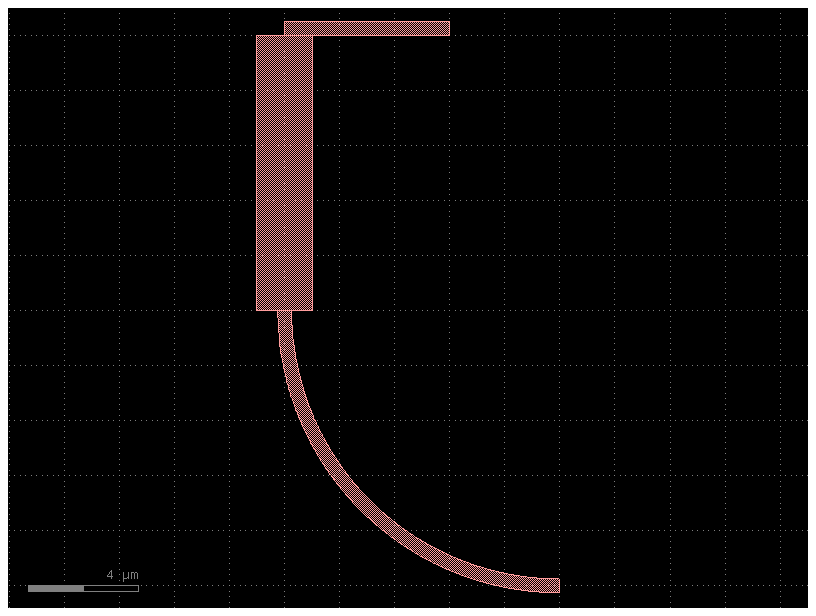

In [1]:
import gdsfactory as gf
import numpy as np
gf.gpdk.PDK.activate()
# Create a rectangular polygon to serve as our waveguide, where we'll define the input and output ports
# The function will return a GDS component with ports, allowing us to concatenate components

@gf.cell
def straight(length:float = 10, width:float = 1, layer:str=(1, 0),):
    c = gf.Component()
    c.add_polygon([(0, 0), (length, 0), (length, width), (0, width)], layer=layer)
    c.add_port(name="o1", center=(0, width / 2), width=width, orientation=180, layer=layer)
    c.add_port(name="o2", center=(length, width / 2), width=width, orientation=0, layer=layer)
    c.info["length"] = length
    c.info["width"] = width 
    return c

'''
First, we define the components, and then we can move or concatenate them. There are plenty of ways to do this—some more efficient than others.
GDSFactory has default functions for basic components as well.
'''
c = gf.Component()

wg1 = c << straight(length=6, width=0.5, layer=(1, 0))
wg2 = c << gf.components.straight(length=10, width=2,cross_section='strip')#layer=(1, 0))
bend = c << gf.components.bend_circular(radius=10, width=0.5, angle=90, layer=(1, 0))

wg1.movey(10)
wg2.drotate(90)
bend.connect(port="o1", other = wg2.ports["o1"], allow_width_mismatch=True)

c.plot()
print(wg1.cell.info['length'])

Now we’ll practice building complex structures from simpler ones, while always keeping access to the connection ports of each structure.

---------------------------------------      EXCERCISE 1       ---------------------------------------
---------------------------------------------------------------------------------------------------------------------

Try creating a function that generates the first letter of your name on a specified layer (MINUS). Make sure the width, size, and connection ports are flexible and adjustable


C:\Users\andre\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\cachetools\_cached.py:185: UserWarning: bend_euler angle should be 90 or 180. Got -45. Use bend_euler_all_angle instead.
  v = func(*args, **kwargs)


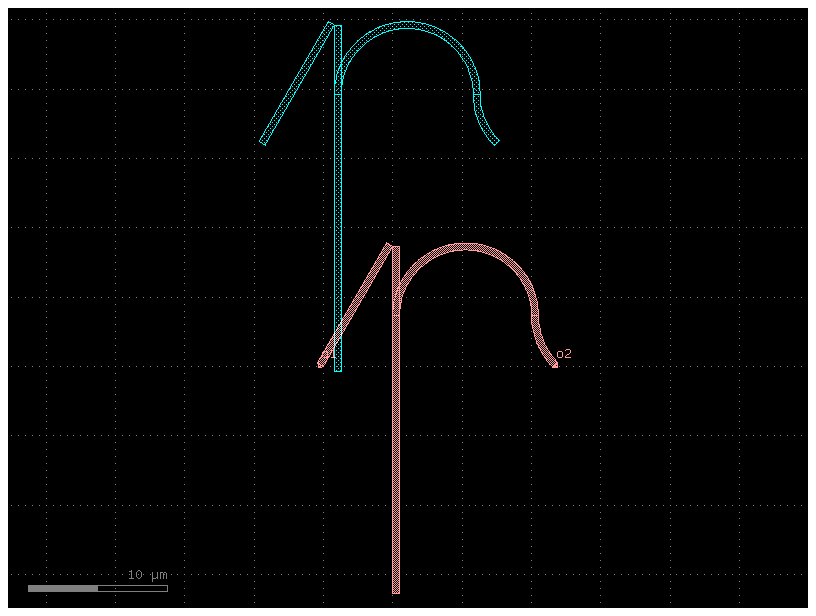

In [2]:
##EXAMPLE##
###########
def p(L = 10, w = 1, layer=(1, 0)):
    c = gf.Component()
    ''' Create elements '''
    S1 = c << straight(L, w, layer)
    S2 = c << straight(2.5*L, w, layer)
    S3 = c << straight(2*L, w, layer)
    B1 = c << gf.components.bend_circular(radius=5, width=w, angle=180, layer=layer)
    B2 = c << gf.components.bend_circular(radius=5, width=w, angle=-45, layer=layer)
    ''' Move and connect elements '''
    S1.drotate(60)
    S2.drotate(-90)
    S2.move([L*np.cos(60*np.pi/180),L*np.sin(60*np.pi/180)])
    S3.connect(port="o1", other = S2.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    S3.mirror_y(S3.ports['o1'].center[1])
    B1.connect(port="o1", other = S3.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    B2.connect(port="o1", other = B1.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    ''' Add and inherit ports '''
    c.add_port("o1", port=S1.ports["o1"],port_type="optical")
    c.add_port("o2", port=B2.ports["o2"],port_type="optical")
    return c

c = gf.Component()

P = c << p(10, 0.5, layer=(1, 0))
P1 = c << p(10, 0.5, layer=(2, 0))

P1.connect(port="o1", other = P.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False)
P1.drotate(105,center = [P.ports['o2'].center[0]/1000,P.ports['o2'].center[1]/1000])
c.add_ports(P.ports)
c.draw_ports()
c.plot()

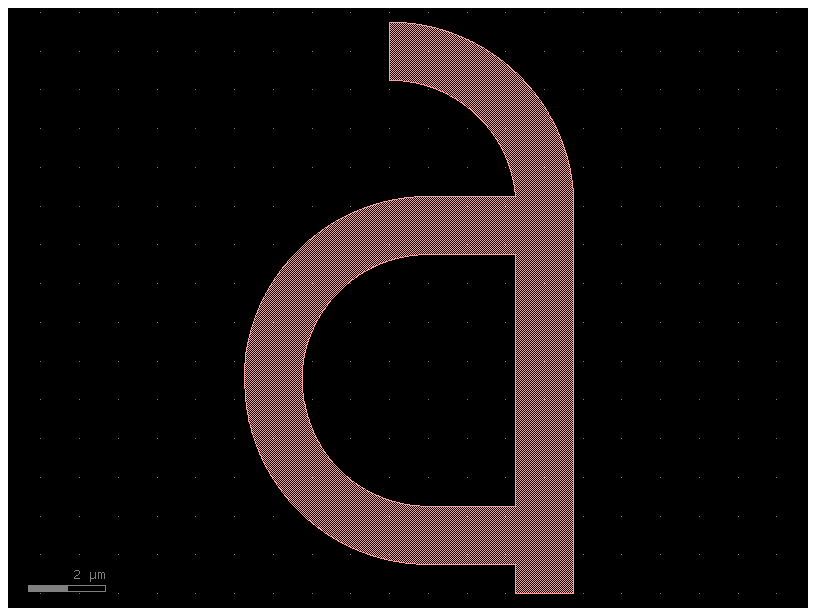

In [3]:
import gdsfactory as gf


def a_min(L = 12, w = 1.5, layer="WG"):
    c = gf.Component()
    
    ''' Create elements '''
    S1 = c << straight(L, w, layer)
    S2 = c << straight(3, w, layer)
    S3 = c << straight(3, w, layer)
    B1 = c << gf.components.bend_circular(radius=4, width=w, angle=180, layer=layer)
    B2 = c << gf.components.bend_circular(radius=4, width=w, angle=90, layer=layer)
    
    ''' Move and connect elements '''
    # Colocamos el tallo vertical en el origen
    S1.rotate(90)
    S1.move(S1.ports["o1"].center, [0, 0])
    
    # Movemos la barriga (C) para que toque la base del tallo
    B1.rotate(180)
    B1.move(B1.ports["o2"].center, [-3,1.5])
    B2.connect("o1", S1.ports["o2"])
    #Colocamos las dos conexiones de la barriga (C) para que toquen el tallo
      
    S2.move(S2.ports["o2"].center, [0, 1.5])
    S3.move(S3.ports["o2"].center, [0, 9.5])
    
    ''' Add and inherit ports '''
    c.add_port("o1", port=B1.ports["o1"], port_type="optical")
    c.add_port("o2", port=B2.ports["o2"], port_type="optical")
    
    # Aplanamos para evitar el error de "off-grid instances" que vimos antes
    c.flatten()
    
    return c

# ==========================================
# Instanciar y visualizar el diseño
# ==========================================
c = gf.Component()


A = c << a_min(L=10, w=1.5, layer="WG")

# Dibujamos y ploteamos
c.add_ports(A.ports)
c.plot() 

---------------------------------------      EXCERCISE 2       ---------------------------------------
---------------------------------------------------------------------------------------------------------------------
Our next objective is to create a real MZI based on multimode interferometers and thermo-optic phase shifters. For this design, we will use the MMIs provided by the 'Foundry' and only need to design the PS section and assemble all the pieces together.

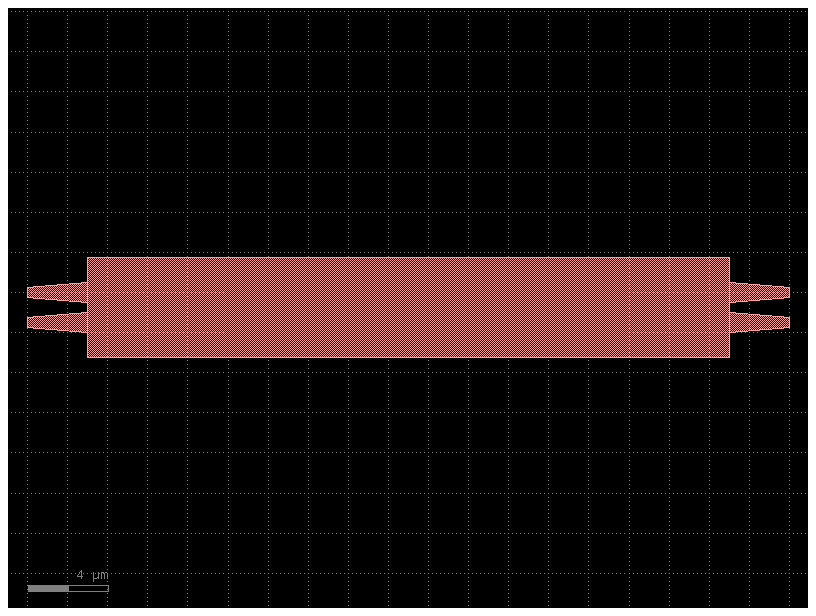

In [4]:
##########################################################################################
##           This code section generates de MMI provided by the "Foundry" 
##########################################################################################
@gf.cell
def Taper(length_taper = 10, w_in = 1,  w_out = 1, layer=(1, 0)):
    ''' This code generates a taper '''
    c = gf.Component()
    c.add_polygon([(0, -w_in/2), (length_taper, -(w_in+w_out)/2), (length_taper, (w_in+w_out)/2), (0, w_in/2)], layer=layer)
    c.add_port(name="o1", center=[0, 0], width=w_in, orientation=180, layer=layer,port_type="optical")
    c.add_port(name="o2", center=[length_taper, 0], width=w_out, orientation=0, layer=layer,port_type="optical")
    c.info["length"] = length_taper
    return c
@gf.cell
def Core(l_core = 10, w_core = 1,layer=(1, 0)):
    ''' This code generates the core of the MMI '''
    c = gf.Component()
    c.add_polygon([(0, -w_core/2), (l_core, -w_core/2), (l_core, w_core/2), (0,w_core/2)], layer=layer)
    c.add_port(name="o1", center=[0, 0], width=w_core, orientation=180, layer=layer,port_type="optical")
    c.add_port(name="o2", center=[l_core, 0], width=w_core, orientation=0, layer=layer,port_type="optical")
    c.info["length"] = l_core
    return c
@gf.cell
def MMI(length_taper = 10, w_in = 1,  w_out = 1, sep = 5, l_core = 20, w_core = 10):
    ''' This code generates the complete MMI using a Core and Tapers '''
    c = gf.Component()
    Taper1 = c << Taper(length_taper, w_in,  w_out, layer=(1, 0))
    Taper2 = c << Taper(length_taper, w_in,  w_out, layer=(1, 0))
    Taper2.dmove((0, -sep)) 
    Core_MMI = c << Core(l_core, w_core,layer=(1, 0))
    Core_MMI.dmove((length_taper, -sep/2)) 

    Taper3 = c << Taper(length_taper, w_in,  w_out, layer=(1, 0))
    Taper4 = c << Taper(length_taper, w_in,  w_out, layer=(1, 0))
    
    Taper3.dmirror_x()
    Taper4.dmirror_x()
    Taper3.dmove((l_core + 2*length_taper , 0))
    Taper4.dmove((l_core + 2*length_taper , -sep))

    c.add_port("o1", port=Taper1.ports["o1"],port_type="optical") 
    c.add_port("o2", port=Taper2.ports["o1"],port_type="optical") 
    c.add_port("o3", port=Taper3.ports["o1"], orientation=180,port_type="optical") 
    c.add_port("o4", port=Taper4.ports["o1"], orientation=180,port_type="optical")
    c.info["length"] = l_core + 2*length_taper
    return c

##########################################################################################
##########################################################################################

c = gf.Component()
mmi = c << MMI(length_taper = 3, w_in = 0.5,  w_out = 0.5, sep = 1.5, l_core = 32, w_core = 5)
c.plot()

First, create the waveguide section with a heater above it. Remember that the heater must be electrically connected at the edges to drive it, and these connections should remain accessible for other functions.

Crossection table:
- Optical waveguide layer: Layer 1
- Electrical/metal layer: Layer 2 
- Heater layer: Layer 3

![My Image](Pic2.png)

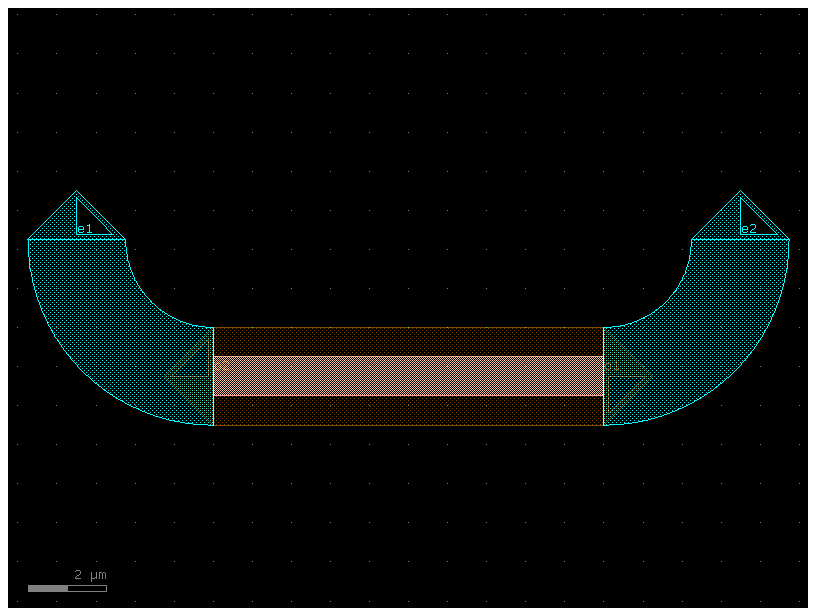

In [5]:
def PS(L = 10, w = 1):
    c = gf.Component()
    ''' Create elements '''
    S1 = c << straight(L, w, layer=(1,0))
    S2 = c << straight(L, 2.5*w, layer=(3,0))
    B1 = c << gf.components.bend_circular(radius = 3.5, angle=90, width=2.5*w, layer=(2,0))
    B2 = c << gf.components.bend_circular(radius = 3.5, angle=90, width=2.5*w, layer=(2,0))
    

    B2.drotate(180)
    S1.connect(port="o2", other = S2.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    S2.connect(port="o2", other = S2.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    B1.connect(port="o2", other = S1.ports["o1"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    B2.connect(port="o1", other = S1.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    B1.connect(port="o2", other = S2.ports["o1"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    B2.connect(port="o1", other = S2.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)

    c.add_port("o1", port=S2.ports["o1"],port_type="optical") 
    c.add_port("o2", port=S2.ports["o2"],port_type="optical") 
    c.add_port("e1", port=B2.ports["o2"],port_type="optical") 
    c.add_port("e2", port=B1.ports["o1"],port_type="optical") 
    
    
    return c

f = gf.Component()

ps = f << PS(10,1)
f.mirror_y()
f.add_ports(ps.ports)
f.draw_ports()
f.plot()
    

In [6]:
def flip(port):
    return dict(
        center=port.center,
        width=port.width,
        orientation=(port.orientation + 180) % 360,
        layer=port.layer,
        port_type="optical"
    )

C:\Users\andre\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\cachetools\_cached.py:185: UserWarning: bend_euler angle should be 90 or 180. Got -90. Use bend_euler_all_angle instead.
  v = func(*args, **kwargs)


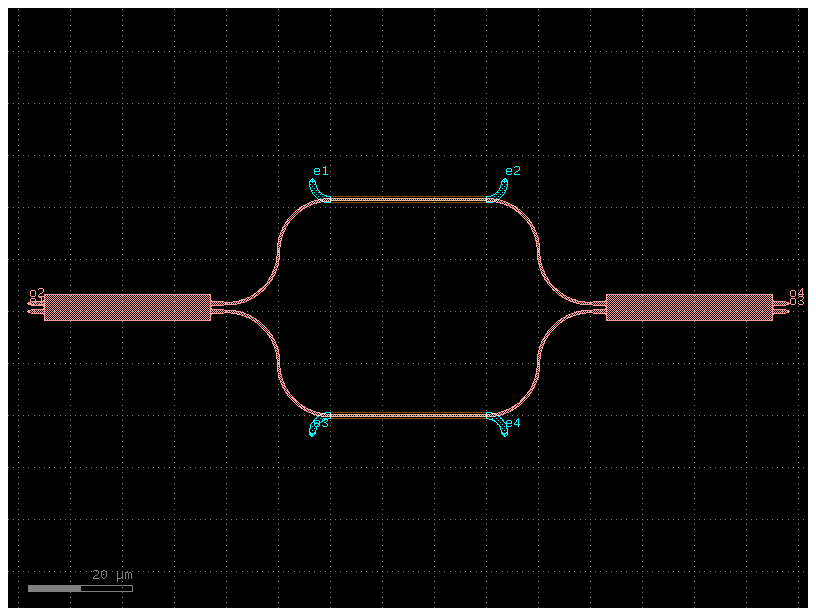

In [7]:
def MZI(L = 10, w = 0.5, layer=(1, 0)):
    c = gf.Component()
    ''' Create elements '''
    mmi1 = c << MMI(length_taper = 3, w_in = 0.5,  w_out = 0.5, sep = 1.5, l_core = 32, w_core = 5)
    mmi2 = c << MMI(length_taper = 3, w_in = 0.5,  w_out = 0.5, sep = 1.5, l_core = 32, w_core = 5)

    # Parte de abajo
    B1 = c << gf.components.bend_circular(radius = 10, angle=-90,width=0.5)
    B2 = c << gf.components.bend_circular(radius = 10, angle=90,width=0.5)
    B3 = c << gf.components.bend_circular(radius = 10, angle=90,width=0.5)
    B4 = c << gf.components.bend_circular(radius = 10, angle=-90,width=0.5)
    ps1 = c << PS(3*L,0.5)

    # Parte de arriba
    B5 = c << gf.components.bend_circular(radius = 10, angle=-90,width=0.5)
    B6 = c << gf.components.bend_circular(radius = 10, angle=90,width=0.5)
    B7 = c << gf.components.bend_circular(radius = 10, angle=90,width=0.5)
    B8 = c << gf.components.bend_circular(radius = 10, angle=-90,width=0.5)
    ps2 = c << PS(3*L,0.5)

    ps1.mirror_y()
    B1.drotate(90)
    B5.mirror_y()
    B6.mirror_x()
    B7.mirror_x()
    B8.mirror_x()
    mmi1.mirror()
    
    # Parte de abajo
    B1.connect(port="o1", other = mmi1.ports["o1"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    B2.connect(port="o1", other = B1.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    ps1.connect(port="o1", other = B2.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    B3.connect(port="o1", other = ps1.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    B4.connect(port="o1", other = B3.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    mmi2.connect(port="o2", other = B4.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)

    # Parte de arriba
    B5.connect(port="o1", other = mmi1.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    B6.connect(port="o1", other = B5.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    ps2.connect(port="o1", other = B6.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    B7.connect(port="o1", other = ps2.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    B8.connect(port="o1", other = B7.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    mmi2.connect(port="o2", other = B8.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)


    c.add_port("e4", port=ps1.ports["e1"], port_type="electrical")
    c.add_port("e3", port=ps1.ports["e2"], port_type="electrical")
    c.add_port("e2", port=ps2.ports["e1"], port_type="electrical")
    c.add_port("e1", port=ps2.ports["e2"], port_type="electrical")

    c.add_port("o2", **flip(mmi1.ports["o4"]))
    c.add_port("o1", **flip(mmi1.ports["o3"]))
    c.add_port("o4", **flip(mmi2.ports["o4"]))
    c.add_port("o3", **flip(mmi2.ports["o3"]))


    
    return c

f = gf.Component()

ps = f << MZI(10,1)
#f.drotate(180)
f.mirror_y()
f.add_ports(ps.ports)
f.draw_ports()
f.plot()

---------------------------------------      EXCERCISE 3       ---------------------------------------
---------------------------------------------------------------------------------------------------------------------
Create a tunale ring resonator using the elements from previous exercises (MZI, Heater...)

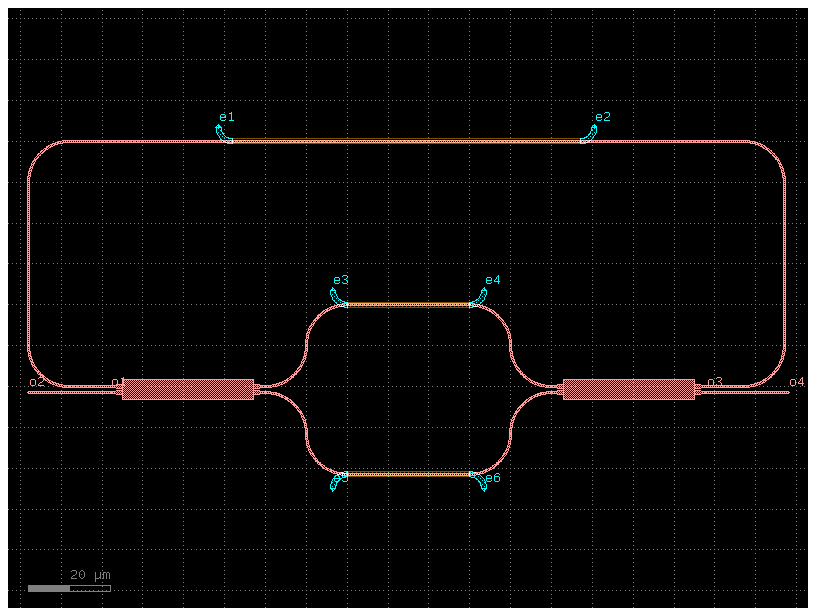

In [8]:
def ring(L = 10, w = 0.5):
    c = gf.Component()

    S1 = c << straight(L, width=.5)
    mzi = c << MZI(10,1)
    B1 = c << gf.components.bend_circular(radius = 10, angle=-90,width=0.5)
    S2 = c << straight(4*L, width=.5)
    B2 = c << gf.components.bend_circular(radius = 10, angle=-90,width=0.5)
    S3 = c << straight(4*L, width=.5)
    ps1 = c << PS(8.5*L,0.5)
    S4 = c << straight(4*L, width=.5)
    B3 = c << gf.components.bend_circular(radius = 10, angle=-90,width=0.5)
    S5 = c << straight(4*L, width=.5)
    B4 = c << gf.components.bend_circular(radius = 10, angle=-90,width=0.5)
    S6 = c << straight(L, width=.5)
    S7 = c << straight(2*L, width=.5)
    S8 = c << straight(2*L, width=.5)


    B1.mirror_y()
    B2.mirror_y()
    ps1.mirror_y()
    B3.mirror_y()
    B4.mirror_y()
    S1.connect(port="o1", other = mzi.ports["o1"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    B1.connect(port="o1", other = S1.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    S2.connect(port="o1", other = B1.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    B2.connect(port="o1", other = S2.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    S3.connect(port="o1", other = B2.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    ps1.connect(port="o1", other = S3.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    S4.connect(port="o1", other = ps1.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    B3.connect(port="o1", other = S4.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    S5.connect(port="o1", other = B3.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    B4.connect(port="o1", other = S5.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    S6.connect(port="o1", other = B4.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    S7.connect(port="o1", other = mzi.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    S8.connect(port="o1", other = mzi.ports["o4"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)

    c.add_port("e5", port=mzi.ports["e1"], port_type="electrical")
    c.add_port("e6", port=mzi.ports["e2"], port_type="electrical")
    c.add_port("e3", port=mzi.ports["e3"], port_type="electrical")
    c.add_port("e4", port=mzi.ports["e4"], port_type="electrical")
    c.add_port("e2", port=ps1.ports["e1"], port_type="electrical")
    c.add_port("e1", port=ps1.ports["e2"], port_type="electrical")

    c.add_port("o4", port=S8.ports["o2"])
    c.add_port("o3", port=S8.ports["o1"])
    c.add_port("o1", port=S7.ports["o1"])
    c.add_port("o2", port=S7.ports["o2"])


    return c

f = gf.Component()

ps = f << ring(10,1)
f.add_ports(ps.ports)
f.draw_ports()
f.plot()